# Key-Value Attention for Thai Karaoke Character-level Machine Translation (Many-to-Many, encoder-decoder)

In this homework, you will create an MT model with attention mechnism that coverts names of Thai 2019 MP candidates from Thai script to Roman(Latin) script. E.g. à¸™à¸´à¸¢à¸¡-->niyom

The use of Pytorch Lightning is optional but recommended. You can use Pytorch if you prefer.

In [1]:
!pip install lightning wandb
!wget https://github.com/Phonbopit/sarabun-webfont/raw/master/fonts/thsarabunnew-webfont.ttf

     â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â” 40.4/40.4 kB 2.5 MB/s eta 0:00:00
   â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â” 815.2/815.2 kB 34.9 MB/s eta 0:00:00
   â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â” 363.4/363.4 MB 3.7 MB/s eta 0:00:00
   â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â” 13.8/13.8 MB 91.2 MB/s eta 0:00:00
   â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â” 24.6/24.6 MB 70.4 MB/s eta 0:00:00
   â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â”â” 883.7/883.7 kB 60.0 MB/s eta 0:00:00
   â”â”â”â”â”â”â”â”â”â”â”â”â

In [2]:
!wandb login

wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize
wandb: Paste an API key from your profile and hit enter, or press ctrl+c to quit: 
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: tangutang-tnp (tangutang-tnp-chulalongkorn-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [3]:
%matplotlib inline
import matplotlib as mpl
mpl.font_manager.fontManager.addfont('thsarabunnew-webfont.ttf') # 3.2+
mpl.rc('font', family='TH Sarabun New')
import torch
# import torchtext
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import lightning as L
import numpy as np

import random

## Load Dataset
We have generated a toy dataset using names of Thai MP candidates in 2019 Thai General Election from elect.in.th's github(https://github.com/codeforthailand/dataset-election-62-candidates) and tltk (https://pypi.org/project/tltk/) library to convert them into Roman script.

```
à¹„à¸à¸£à¸ªà¸µà¸«à¹Œ kraisi
à¸žà¸±à¸Šà¸£à¸µ phatri
à¸˜à¸µà¸£à¸° thira
à¸§à¸¸à¸’à¸´à¸à¸£ wutthikon
à¹„à¸ªà¸§ sawai
à¸ªà¸±à¸¡à¸ à¸²à¸©à¸“à¹Œ  samphat
à¸§à¸¨à¸´à¸™ wasin
à¸—à¸´à¸™à¸§à¸±à¸’à¸™à¹Œ thinwat
à¸¨à¸±à¸à¸”à¸´à¸™à¸±à¸¢ sakdinai
à¸ªà¸¸à¸£à¸¨à¸±à¸à¸”à¸´à¹Œ surasak
```


In [4]:
!wget https://raw.githubusercontent.com/ekapolc/nlp_2019/master/HW8/mp_name_th_en.csv

--2025-02-20 16:07:32--  https://raw.githubusercontent.com/ekapolc/nlp_2019/master/HW8/mp_name_th_en.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 324399 (317K) [text/plain]
Saving to: â€˜mp_name_th_en.csvâ€™

mp_name_th_en.csv   100%[===================>] 316.80K  --.-KB/s    in 0.006s  

2025-02-20 16:07:33 (47.9 MB/s) - â€˜mp_name_th_en.csvâ€™ saved [324399/324399]



In [5]:
import csv

with open('mp_name_th_en.csv') as csvfile:
    readCSV = csv.reader(csvfile, delimiter=',')
    name_th = []
    name_en = []
    for row in readCSV:
        temp_th = row[0]
        temp_en = row[1]

        name_th.append(temp_th)
        name_en.append(temp_en)

In [6]:
for th, en in zip(name_th[:10],name_en[:10]):
    print(th,en)

à¹„à¸à¸£à¸ªà¸µà¸«à¹Œ kraisi
à¸žà¸±à¸Šà¸£à¸µ phatri
à¸˜à¸µà¸£à¸° thira
à¸§à¸¸à¸’à¸´à¸à¸£ wutthikon
à¹„à¸ªà¸§ sawai
à¸ªà¸±à¸¡à¸ à¸²à¸©à¸“à¹Œ  samphat
à¸§à¸¨à¸´à¸™ wasin
à¸—à¸´à¸™à¸§à¸±à¸’à¸™à¹Œ thinwat
à¸¨à¸±à¸à¸”à¸´à¸™à¸±à¸¢ sakdinai
à¸ªà¸¸à¸£à¸¨à¸±à¸à¸”à¸´à¹Œ surasak


## TODO1: Preprocess dataset
* You will need 2 vocabularies (1 for input and another for output)
* DON'T FORGET TO INCLUDE special token for padding (for both input and output)
* DON'T FORGET TO INCLUDE special token for the end of word symbol (output)

In [7]:
#Preprocessing
input_chars = list(set(''.join(name_th)))
output_chars = list(set(''.join(name_en)))
data_size, vocab_size = len(name_th), len(input_chars)+1
output_vocab_size = len(output_chars)+2#+2 for special end of sentence token/PADDING
print('There are %d lines and %d unique characters in your input data.' % (data_size, vocab_size))
maxlen = len( max(name_th, key=len)) #max input length
maxlen_out = len( max(name_en, key=len)) #max input length

There are 10887 lines and 65 unique characters in your input data.


In [8]:
print("Max input length:", maxlen)
print("Max output length:", maxlen_out)

Max input length: 20
Max output length: 19


In [9]:
import torch
# Step 1: Create Sorted Vocabularies
thai_voc = sorted(input_chars)  # Extract unique Thai characters
eng_voc = sorted(output_chars)  # Extract unique English characters

# Step 2: Add Special Tokens
thai_voc.insert(0, '<PAD>')
eng_voc.insert(0, '<PAD>')
eng_voc.append('</s>')  # End-of-sequence token for output

# Step 3: Create Character-to-Index (stoi) and Index-to-Character (itos) Mappings
input_stoi = {s: i for i, s in enumerate(thai_voc)}
input_itos = {i: s for i, s in enumerate(thai_voc)}

output_stoi = {s: i for i, s in enumerate(eng_voc)}
output_itos = {i: s for i, s in enumerate(eng_voc)}

# Step 4: Define Encoding and Decoding Functions
input_encode = lambda x: [input_stoi[i] for i in x]
input_decode = lambda x: ''.join([input_itos[i] for i in x])

output_encode = lambda x: [output_stoi[i] for i in x]
output_decode = lambda x: ''.join([output_itos[i] for i in x])

# Step 5: Encode and Decode Example Names
thai_example = "à¸žà¸±à¸Šà¸£à¸µ"
english_example = "phatri"

print(input_encode(thai_example))  # Encode Thai
print(input_decode(input_encode(thai_example)))  # Decode Thai

print(output_encode(english_example))  # Encode English
print(output_decode(output_encode(english_example)))  # Decode English

# Step 6: Print Vocab Dictionaries and Sizes
print(input_stoi)
print(len(input_stoi))  # Number of unique Thai characters (including <PAD>)

print(output_stoi)
print(len(output_stoi))  # Number of unique English characters (including <PAD> and </s>)


[29, 45, 9, 34, 49]
à¸žà¸±à¸Šà¸£à¸µ
[16, 9, 2, 19, 17, 10]
phatri
{'<PAD>': 0, ' ': 1, 'à¸': 2, 'à¸‚': 3, 'à¸„': 4, 'à¸†': 5, 'à¸‡': 6, 'à¸ˆ': 7, 'à¸‰': 8, 'à¸Š': 9, 'à¸‹': 10, 'à¸Œ': 11, 'à¸': 12, 'à¸Ž': 13, 'à¸': 14, 'à¸': 15, 'à¸‘': 16, 'à¸’': 17, 'à¸“': 18, 'à¸”': 19, 'à¸•': 20, 'à¸–': 21, 'à¸—': 22, 'à¸˜': 23, 'à¸™': 24, 'à¸š': 25, 'à¸›': 26, 'à¸œ': 27, 'à¸': 28, 'à¸ž': 29, 'à¸Ÿ': 30, 'à¸ ': 31, 'à¸¡': 32, 'à¸¢': 33, 'à¸£': 34, 'à¸¥': 35, 'à¸§': 36, 'à¸¨': 37, 'à¸©': 38, 'à¸ª': 39, 'à¸«': 40, 'à¸¬': 41, 'à¸­': 42, 'à¸®': 43, 'à¸°': 44, 'à¸±': 45, 'à¸²': 46, 'à¸³': 47, 'à¸´': 48, 'à¸µ': 49, 'à¸¶': 50, 'à¸·': 51, 'à¸¸': 52, 'à¸¹': 53, 'à¹€': 54, 'à¹': 55, 'à¹‚': 56, 'à¹ƒ': 57, 'à¹„': 58, 'à¹‡': 59, 'à¹ˆ': 60, 'à¹‰': 61, 'à¹Š': 62, 'à¹‹': 63, 'à¹Œ': 64}
65
{'<PAD>': 0, '-': 1, 'a': 2, 'b': 3, 'c': 4, 'd': 5, 'e': 6, 'f': 7, 'g': 8, 'h': 9, 'i': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'r': 17, 's': 18, 't': 19, 'u': 20, 'w': 21, 'y': 22, '</s>': 23}
24


In [10]:
from torch.utils.data import Dataset, DataLoader

In [11]:
class NameDataset(Dataset):
  def __init__(self, X, y):
    self.encoded = X.long()
    self.label = y.long()

  def __getitem__(self, idx):
    return {"x" :self.encoded[idx], "y":self.label[idx]}

  def __len__(self):
    return len(self.encoded)

In [12]:
class NameDataModule(L.LightningDataModule):

  def __init__(self, train_data, y, batch_size, num_workers=0):
      super().__init__()
      self.train_data = train_data
      self.y = y
      self.batch_size = batch_size
      self.num_workers = num_workers


  def setup(self, stage: str):
    pass

  def collate_fn(self, batch):
      one_hot_x = torch.stack([F.one_hot(b["x"], num_classes=len(input_stoi)) for b in batch])
      return {"x": one_hot_x.float(), "y": torch.stack([b["y"] for b in batch])}

  def train_dataloader(self):
      train_dataset = NameDataset(self.train_data, self.y)
      train_loader = DataLoader(train_dataset,
                                batch_size = self.batch_size,
                                shuffle = True,
                                collate_fn = self.collate_fn,
                                num_workers = self.num_workers)

      return train_loader


In [13]:
X_encoded = []
for line in name_th:
    line = [l for l in line] #change from string to list
    X_encoded.append(torch.tensor(input_encode(line)))
y_encoded = []
for line in name_en:
    line = [l for l in line] #change from string to list
    y_encoded.append(torch.tensor(output_encode(line)))

X = nn.utils.rnn.pad_sequence(X_encoded, batch_first = True)

In [14]:
# Define batch size
batch_size = 4

# Create DataModule instance
data_module = NameDataModule(X_encoded, y_encoded, batch_size=batch_size)

In [15]:
print(X_encoded[1])
print(y_encoded[1])

tensor([29, 45,  9, 34, 49])
tensor([16,  9,  2, 19, 17, 10])


In [16]:
Y = nn.utils.rnn.pad_sequence(y_encoded, batch_first = True)

In [17]:
print(X.shape)
print(X[:3])
print(Y.shape)
print(Y[:3])

torch.Size([10887, 20])
tensor([[58,  2, 34, 39, 49, 40, 64,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
          0,  0],
        [29, 45,  9, 34, 49,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
          0,  0],
        [23, 49, 34, 44,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
          0,  0]])
torch.Size([10887, 19])
tensor([[11, 17,  2, 10, 18, 10,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
          0],
        [16,  9,  2, 19, 17, 10,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
          0],
        [19,  9, 10, 17,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
          0]])


# Attention Mechanism


## TODO 2: Code your own (key-value) attention mechnism
* PLEASE READ: you DO NOT have to follow all the details in (Daniluk, et al. 2017). You just need to create a key-value attention mechanism where the "key" part of the mechanism is used for attention score calculation, and the "value" part of the mechanism is used to encode information to create a context vector.  
* fill code for one_step_attention function



In [18]:
s_prev = torch.tensor([1. ,2.,3.])
print(s_prev)
s_prev.unsqueeze(0)
print(s_prev)
s_prev_repeat = s_prev.unsqueeze(0).repeat(3,3)
print(s_prev_repeat)

tensor([1., 2., 3.])
tensor([1., 2., 3.])
tensor([[1., 2., 3., 1., 2., 3., 1., 2., 3.],
        [1., 2., 3., 1., 2., 3., 1., 2., 3.],
        [1., 2., 3., 1., 2., 3., 1., 2., 3.]])


In [19]:
def one_step_attention(h, s_prev,linear_1, linear_2):

    #Split into Key-Value
    key_dim = h.shape[-1]
    key, value = torch.split(h, [key_dim//2,key_dim//2], dim=-1)
    s_prev = s_prev.unsqueeze(1).repeat(1, key.shape[1], 1)

    #do concat with s_prev.
    concat = torch.cat([key, s_prev], dim=-1)

    #hint: you will need to use s_prev.repeat(...) somehow so that it has the same dimension as the key
    #hint2: s_prev.unsqueeze() could also be useful


    #Attention function###
    # use layer(s) from your model to calculate attention_scores and then softmax
    # calculate a context vector
    e = F.tanh(linear_1(concat))
    energies = F.relu(linear_2(e))
    attention_scores = F.softmax(energies, dim=1)  # (batch_size, seq_len, 1)
    context = torch.sum(attention_scores * value, dim=1)
    return context, attention_scores

# Translation Model

## TODO3: Create and train your encoder/decoder model here

In [20]:
max_output_length = len(max(Y,key=len))
max_output_length

19

In [21]:
class AttentionModel(L.LightningModule):
    def __init__(self,learning_rate,criterion):

        super().__init__()
        self.n_h = 32#hidden dimensions for encoder
        self.n_s = 64#hidden dimensions for decoder
        self.learning_rate = learning_rate
        self.criterion = criterion
        #encoder can be any RNN of your choice
        bidirection = True
        self.num_directions = 2 if bidirection else 1
        self.lstm = nn.LSTM(len(input_stoi), self.n_h, bidirectional=bidirection, batch_first=True)


        #decoder has to be (any) RNNCell since we will need to calculate attention for each timestep manually
        self.decoder_lstm_cell = nn.LSTMCell(self.n_s//2, self.n_s)
        self.output_layer = nn.Linear(self.n_s, len(output_stoi))
        #attention
        self.linear_1 = nn.Linear(self.n_h * self.num_directions * 3 // 2, self.n_h)
        self.linear_2 = nn.Linear(self.n_h, 1)


    def forward(self, src, return_attention=False): #use return_attention only when you want to get the attention scores for visualizing
        #pass the input to the encoder
        lstm_out, _ = self.lstm(src)
        #Initialize the LSTM states. We have to do this since we are using LSTMCell (https://pytorch.org/docs/stable/generated/torch.nn.LSTMCell.html)
        #These states will get updated while we are decoding
        decoder_s = torch.randn(src.shape[0], self.n_s).to(self.decoder_lstm_cell.weight_ih.device)
        decoder_c = torch.randn(src.shape[0], self.n_s).to(self.decoder_lstm_cell.weight_ih.device)

        #Iterate until max_output_length (Decoding)
        prediction = torch.zeros((src.shape[0], max_output_length, len(output_stoi))).to(self.decoder_lstm_cell.weight_ih.device)
        attention_scores = [] #to store the score for each step
        for t in range(max_output_length):

            #Perform one step of the attention mechanism to calculate the context vector at timestep t
            context, attention_score = one_step_attention(lstm_out, decoder_s, self.linear_1, self.linear_2)
            attention_scores.append(attention_score)
            # Feed the context vector to the decoder.
            decoder_s, decoder_c = self.decoder_lstm_cell(context, (decoder_s, decoder_c))
            # Pass the decoder hidden output to the output layer (softmax)
            out = self.output_layer(decoder_s)
            # Put the predicted output into the list for this timestep
            prediction[:, t] = out

        return (prediction, attention_scores if return_attention else None)

    def training_step(self, batch, batch_idx):
        src = batch['x']
        target = batch['y']
        prediction,_ = self(src)
        prediction = prediction.reshape(-1, len(output_stoi))
        target = target.reshape(-1)
        loss = self.criterion(prediction, target)
        self.log("train_loss", loss)
        return loss

    def predict_step(self, batch, batch_idx, dataloader_idx=0):
        src = batch['x']
        with torch.no_grad():
          prediction, attention_scores = self(src, return_attention=True)
          prediction = F.softmax(prediction, dim=-1)
          prediction = torch.argmax(prediction, dim=-1)
          for pred in prediction:
            print("".join([output_itos.get(idx.item(), '<UNK>') for idx in pred.cpu()]))
        return prediction, attention_scores

    def configure_optimizers(self):
        return optim.Adam(self.parameters(), lr=self.learning_rate)

In [22]:
data_module = NameDataModule(X, Y,batch_size=4096)
criterion = nn.CrossEntropyLoss()
learning_rate = 0.01
model = AttentionModel(criterion=criterion, learning_rate=learning_rate)

In [23]:
from lightning import Trainer
from lightning.pytorch.loggers import WandbLogger
wandb_logger = WandbLogger(project="hw3.1_attention")

In [24]:
trainer = L.Trainer(
    max_epochs=400,
    logger=wandb_logger
)

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs


In [25]:
trainer.fit(model, data_module)

wandb: Currently logged in as: tangutang-tnp (tangutang-tnp-chulalongkorn-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Using wandb-core as the SDK backend.  Please refer to https://wandb.me/wandb-core for more information.


INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: 
  | Name              | Type             | Params | Mode 
---------------------------------------------------------------
0 | criterion         | CrossEntropyLoss | 0      | train
1 | lstm              | LSTM             | 25.3 K | train
2 | decoder_lstm_cell | LSTMCell         | 25.1 K | train
3 | output_layer      | Linear           | 1.6 K  | train
4 | linear_1          | Linear           | 3.1 K  | train
5 | linear_2          | Linear           | 33     | train
---------------------------------------------------------------
55.1 K    Trainable params
0         Non-trainable params
55.1 K    Total params
0.221     Total estimated model params size (MB)
6         Modules in train mode
0         Modules in eval mode
INFO:lightning.pytorch.callbacks.model_summary:
  | Name              | Type             | Params | Mode 
-----------------------------

Training: |          | 0/? [00:00<?, ?it/s]

INFO: `Trainer.fit` stopped: `max_epochs=400` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=400` reached.


# Test Your Model

## TODO4: Test your model on 5 examples of your choice including your name!

Example Output:
```
prayutthatha</s></s>aa</s></s>a</s>
somchai</s></s></s></s>a</s></s>a</s></s></s></s></s>
thanathon</s></s></s></s></s></s></s></s></s></s></s>
newin</s>i</s></s></s></s></s></s></s></s></s></s></s></s></s>
suthep</s>he</s></s></s></s></s></s></s></s></s></s></s>
prawit</s></s></s></s></s></s></s></s></s></s></s></s></s></s>
chatchachatti</s></s>i</s></s></s></s>
```

<font color='blue'>Paste your model predictions in MyCourseVille</font>

In [26]:
EXAMPLES = ['à¸›à¸£à¸°à¸¢à¸¸à¸—à¸˜','à¸ªà¸¡à¸Šà¸²à¸¢','à¸˜à¸™à¸²à¸˜à¸£','à¹€à¸™à¸§à¸´à¸™','à¸ªà¸¸à¹€à¸—à¸ž','à¸›à¸£à¸°à¸§à¸´à¸•à¸£à¹Œ','à¸Šà¸±à¸Šà¸Šà¸²à¸•à¸´']
predict_data = []
for line in EXAMPLES:
    line = [l for l in line] #change from string to list
    predict_data.append(torch.tensor(input_encode(line)))

print(len(predict_data))
def collate_fn(batch):
    one_hot_x = torch.stack([F.one_hot(b["x"], num_classes=len(input_stoi)) for b in batch])
    return {"x": one_hot_x.float()}

predict_data = nn.utils.rnn.pad_sequence(predict_data, batch_first = True)
predict_dataset = NameDataset(predict_data, torch.tensor([torch.tensor(0)]*len(predict_data)))
predict_loader = DataLoader(predict_dataset,
                          batch_size = 1,
                          shuffle = False,
                          collate_fn = collate_fn,
                          num_workers = 0)

7


In [27]:
model.eval()

AttentionModel(
  (criterion): CrossEntropyLoss()
  (lstm): LSTM(65, 32, batch_first=True, bidirectional=True)
  (decoder_lstm_cell): LSTMCell(32, 64)
  (output_layer): Linear(in_features=64, out_features=24, bias=True)
  (linear_1): Linear(in_features=96, out_features=32, bias=True)
  (linear_2): Linear(in_features=32, out_features=1, bias=True)
)

In [28]:
output = trainer.predict(model, predict_loader)

INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

praautthha<PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD>
somchaiy<PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD>
thanatthon<PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD>
newin<PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD>
suthepp<PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD>
prawit<PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD><PAD>
chatchcchatattii<PAD><PAD><PAD>


## TODO 5: Show your visualization of attention scores on one of your example

<font color='blue'>Paste your visualization image in MyCourseVille</font>

In [29]:
%matplotlib inline
import seaborn as sns
import matplotlib.pyplot as plt

In [30]:
prediction, attention_scores = zip(*output)

In [31]:
sample_pred = prediction[-1].cpu().numpy().tolist()[0]  # Convert to list
sample_pred = [p for p in sample_pred if p != 0]  # Remove padding tokens
sample_attention_scores = attention_scores[-1]

# Convert attention scores to NumPy array
attn_viz = torch.stack(sample_attention_scores).squeeze().cpu().numpy()
attn_viz = attn_viz[:len(EXAMPLES[-1])+1, :len(sample_pred)+1]

# Decode output tokens
output_text = [output_itos.get(idx, "<UNK>") for idx in sample_pred]
output_text.append("<PAD>")

# Decode input tokens
xlabels = [c for c in EXAMPLES[-1]]
xlabels.append("<PAD>")

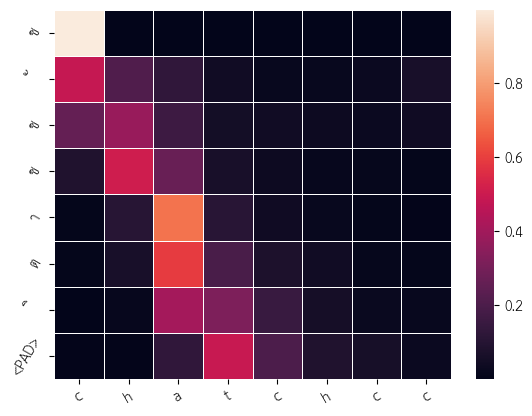

In [35]:
# Get the current tick locations
xticks = ax.get_xticks()

# Adjust the length of xticklabels to match the length of ticks
output_text = output_text[:len(xticks)]

# Set xticklabels
ax = sns.heatmap(attn_viz, linewidth=0.5)
ax.set_xticklabels(output_text, rotation=30)
ax.set_yticklabels(xlabels, rotation=60)
plt.show()